# ST40 Li powder dropper, full 3-D torus: where does the lithium land?

Run of `3d/in.openedge` (constant feed 3.0e21 atoms/s from the dropper patch at
phi = 0, `chem_mode neutral`: Li is removed at ionization, everything that reaches
the wall is absorbed), read from `output` and `output/stdout.openedge`.
Coordinates: x = R cos phi, y = R sin phi, z = Z. Each `landing.<step>.vtu` is one
20 ms window: per wall triangle, `compute surf` columns [1] grain hits,
[2] grain "flux" (fnum-normalised, not used), [3] Li hits, [4] Li number flux
[atoms/m^2/s]. `fix ave/surf` samples single timesteps every NEVERY steps and averages
them, so wall hits and fluxes are unbiased per-step averages. The emitter writes its
grains into the tally of the dropper triangles, and because the emission cadence is a
multiple of NEVERY those bursts are always sampled: the dropper triangles are excluded
from the grain landing. Comparison window = (120000, 200000] (steady only if the inventories are flat there).

In [1]:
import re, glob
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.path import Path as MplPath
import pyvista as pv

CASE = Path.cwd().resolve()
if CASE.name == "notebooks":
    CASE = CASE.parent
OUT = CASE / "output"
LOG = CASE / "output/stdout.openedge"
STEADY_FROM = 120000
STEADY_TO = 200000
DT = 2.0e-6                       # s per step
deck = open(CASE / "in.openedge").read()
NEVERY = int(re.search(r"ave/surf\s+\S+\s+(\d+)", deck).group(1))      # compute surf sampling interval
FNUM = float(re.search(r"variable fnum\s+index\s+(\S+)", deck).group(1))
NWEIGHT = float(re.search(r"variable nweight\s+index\s+(\S+)", deck).group(1))
gsp = re.search(r"variable gspecies\s+index\s+(\S+)", deck).group(1)        # grain species file of the deck
molwt = float([l.split() for l in open(CASE / gsp) if l.startswith("droplet")][0][1])
ATOMS_PER_GRAIN = 0 or molwt / 6.941      # atoms per physical grain (from the species file unless overridden)
FEED = 3e+21                     # atoms/s; 0 = time-dependent source, no percentages
def pct(x): return f"{100*x/FEED:.1f}% of feed" if FEED > 0 else "(time-dependent feed)"
import json
CASE_JSON = OUT.parent / "case.json"          # written by scripts/run_matrix.sh: the -var overrides of the deck
if CASE_JSON.exists():
    cj = json.load(open(CASE_JSON))
    NWEIGHT = float(cj.get("nweight", NWEIGHT)); ATOMS_PER_GRAIN = float(cj.get("atoms_per_grain", ATOMS_PER_GRAIN)); FEED = float(cj.get("feed", FEED))
    print("matrix case:", cj)
plt.rcParams.update({"font.size": 11, "figure.dpi": 110})
print("reading", OUT, LOG.name)

def read_loop(path):
    """2-D wall loop in axi layout -> (R, Z) in file order."""
    pts, mode = {}, None
    for line in open(path):
        t = line.split()
        if not t: continue
        if t[0] == "Points": mode = "p"; continue
        if t[0] == "Lines": mode = "l"; continue
        if mode == "p" and len(t) == 3 and t[0].isdigit():
            pts[int(t[0])] = (float(t[2]), float(t[1]))
    return np.array([pts[i] for i in sorted(pts)])

WALL = read_loop(CASE.parent / "input/st40_wall_axi.surf")      # (R, Z), 141 points
CORE = read_loop(CASE.parent / "input/st40_core.surf")          # (R, Z), 90 points
NSEG = len(WALL)
hdr = open(CASE / "input/st40_wall_3d.surf").readline()
NPHI = int(re.search(r"(\d+) strips", hdr).group(1))
DPHI = 360.0 / NPHI
drop_ids = []
for line in open(CASE / "input/st40_groups.inc"):
    t = line.split()
    if t[:1] == ["group"]: drop_ids += list(range(int(t[5]), int(t[6]) + 1))
drop_k = sorted({(i - 1) // (2 * NPHI) for i in drop_ids})
drop_j = sorted({((i - 1) % (2 * NPHI)) // 2 for i in drop_ids})
print(f"{NSEG} wall segments x {NPHI} strips; dropper segments {drop_k}, strips {drop_j}; ave/surf nevery {NEVERY}, fnum {FNUM:g}, nweight {NWEIGHT:g}")

# poloidal wall coordinate s [m]: arc length along the loop, 0 at the dropper
seg_len = np.hypot(*(np.roll(WALL, -1, axis=0) - WALL).T)
s_edge = np.concatenate([[0.0], np.cumsum(seg_len)])
s_mid = 0.5 * (s_edge[:-1] + s_edge[1:])
s0 = s_mid[drop_k].mean()
s_mid_d = s_mid - s0
phi_c = (np.arange(NPHI) - NPHI // 2) * DPHI          # strip centres, dropper at 0
seg_mid = 0.5 * (WALL + np.roll(WALL, -1, axis=0))      # (R, Z) of each segment

reading /Users/42d/OpenEdge/examples/workflows/particulates/st40_lithium_powder_dropper/openedge/3d/output stdout.openedge
141 wall segments x 240 strips; dropper segments [15, 16], strips [120]; ave/surf nevery 10, fnum 2e+11, nweight 8


/Users/42d/venvs/openedge-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inventories, ionization rate and load balance from the log

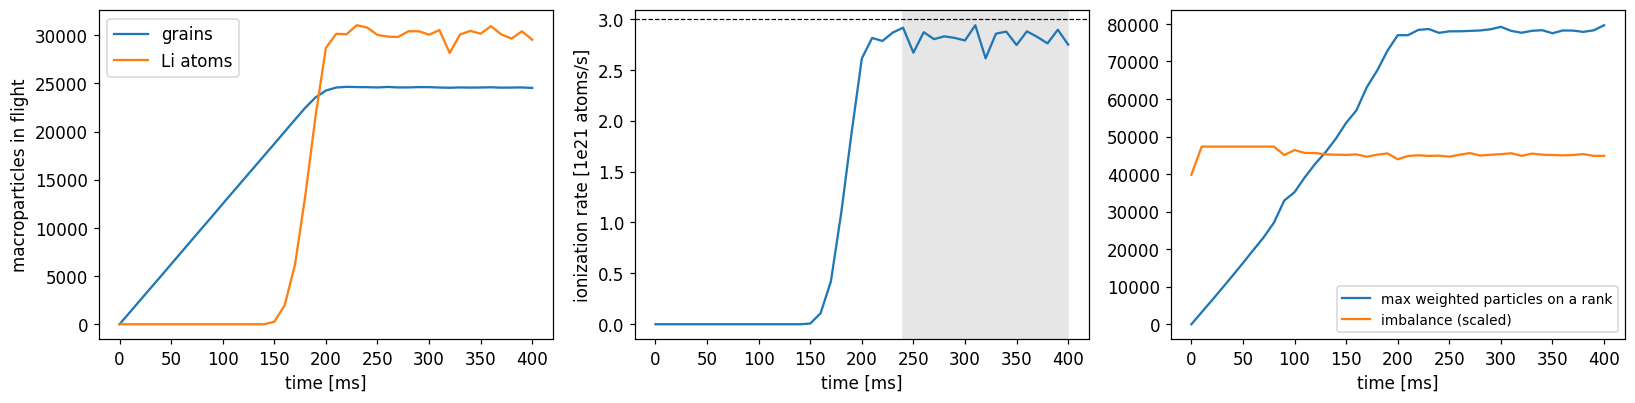

steady ionization 2.806e+21 atoms/s 93.5% of feed; grains 24584, Li 30040 in flight


In [2]:
cols = rows = None
if not LOG.exists():
    print("no log for this run: inventories and ionization rate unavailable (log was overwritten)")
    SP_STEADY = float("nan")
for line in (open(LOG) if LOG.exists() else []):
    t = line.split()
    if t[:2] == ["Step", "CPU"]: cols = t; rows = []; continue
    if cols is not None and len(t) == len(cols) and t[0].isdigit():
        rows.append([float(v) for v in t])
    elif cols is not None and t[:1] == ["Loop"]: break
if cols is None: rows = []
S = {k: np.array([r[i] for r in rows]) for i, k in enumerate(cols)} if cols else {}
if S:
  t_ms = S["Step"] * DT * 1e3
  fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
  ax[0].plot(t_ms, S["c_cnt[1]"], label="grains"); ax[0].plot(t_ms, S["c_cnt[2]"], label="Li atoms")
  ax[0].set(xlabel="time [ms]", ylabel="macroparticles in flight"); ax[0].legend()
  ax[1].plot(t_ms, S["c_cSp_tot"] / 1e21)
  if FEED > 0: ax[1].axhline(FEED / 1e21, ls="--", c="k", lw=0.8)
  ax[1].set(xlabel="time [ms]", ylabel="ionization rate [1e21 atoms/s]"); ax[1].axvspan(STEADY_FROM * DT * 1e3, STEADY_TO * DT * 1e3, color="0.9")
  ax[2].plot(t_ms, S["f_fbal[1]"], label="max weighted particles on a rank"); ax[2].plot(t_ms, S["f_fbal[2]"] * S["f_fbal[1]"].max() / 2, label="imbalance (scaled)")
  ax[2].set(xlabel="time [ms]"); ax[2].legend(fontsize=9)
  plt.tight_layout(); plt.show()
  steady = (S["Step"] > STEADY_FROM) & (S["Step"] <= STEADY_TO)
  SP_STEADY = S["c_cSp_tot"][steady].mean()
  print(f"steady ionization {SP_STEADY:.3e} atoms/s {pct(SP_STEADY)}; "
        f"grains {S['c_cnt[1]'][steady].mean():.0f}, Li {S['c_cnt[2]'][steady].mean():.0f} in flight")

## Landing map

Triangle ids follow `make_geometry.py`: 2-D segment k owns ids `2*NPHI*k+1 .. 2*NPHI*(k+1)`,
strip j the pair `2*NPHI*k + 2*j + 1, +2`, so the wall is a regular (segment, strip) lattice.
Per quad: Li deposition rate = sum over its two triangles of flux x area [atoms/s];
grain rate = hits per step / dt x nweight [grains/s].

In [3]:
def load_landing(path):
    m = pv.read(path)
    order = np.argsort(np.asarray(m["id"]))
    ids = np.asarray(m["id"])[order]
    assert ids[0] == 1 and ids[-1] == 2 * NPHI * NSEG
    P = np.asarray(m.points); T = m.cells.reshape(-1, 4)[:, 1:][order]
    v0, v1, v2 = P[T[:, 0]], P[T[:, 1]], P[T[:, 2]]
    area = 0.5 * np.linalg.norm(np.cross(v1 - v0, v2 - v0), axis=1)
    n_grain = np.asarray(m["f_fland[1]"])[order]                   # hits per step (sampled)
    li_flux = np.asarray(m["f_fland[4]"])[order]                   # atoms/m^2/s
    n_grain[np.isin(ids, drop_ids)] = 0.0                          # emission bursts, not landings
    k = (ids - 1) // (2 * NPHI); j = ((ids - 1) % (2 * NPHI)) // 2
    def quad(v):
        a = np.zeros((NSEG, NPHI)); np.add.at(a, (k, j), v); return a
    return dict(area=quad(area), li_rate=quad(li_flux * area), grain_rate=quad(n_grain) / DT * NWEIGHT)

files = sorted(glob.glob(str(OUT / "landing.*.vtu")), key=lambda p: int(re.findall(r"\d+", p)[-1]))
steps = np.array([int(re.findall(r"\d+", p)[-1]) for p in files])
use = [f for f, s in zip(files, steps) if STEADY_FROM < s <= STEADY_TO]        # file <step> = END of its window
print(f"{len(files)} windows, averaging {len(use)} in ({STEADY_FROM}, {STEADY_TO}]")
L = [load_landing(f) for f in use]
AREA = L[0]["area"]
LI = np.mean([d["li_rate"] for d in L], axis=0)        # atoms/s per quad
GR = np.mean([d["grain_rate"] for d in L], axis=0)     # grains/s per quad
LI_FLUX = LI / AREA
li_wall = LI.sum(); gr_wall = GR.sum()
print(f"Li to wall  {li_wall:.3e} atoms/s  {pct(li_wall)}")
print(f"grains to wall {gr_wall:.3e} grains/s (dropper triangles excluded)")
print(f"ionized {SP_STEADY:.3e} atoms/s {pct(SP_STEADY)}")
if FEED > 0:
    GRAIN_FEED = FEED / ATOMS_PER_GRAIN
    print(f"fed {GRAIN_FEED:.3e} grains/s: {100*gr_wall/GRAIN_FEED:.0f}% of the grains reach the wall; "
          f"by difference {100*(FEED-SP_STEADY-li_wall)/FEED:.0f}% of the fed lithium reaches the wall as unablated grain mass "
          "(steady inventories: feed = ionized + Li atoms to wall + grain mass to wall)")

21 windows, averaging 8 in (120000, 200000]


Li to wall  8.560e+18 atoms/s  0.3% of feed
grains to wall 4.185e+05 grains/s (dropper triangles excluded)
ionized 2.806e+21 atoms/s 93.5% of feed
fed 9.893e+05 grains/s: 42% of the grains reach the wall; by difference 6% of the fed lithium reaches the wall as unablated grain mass (steady inventories: feed = ionized + Li atoms to wall + grain mass to wall)


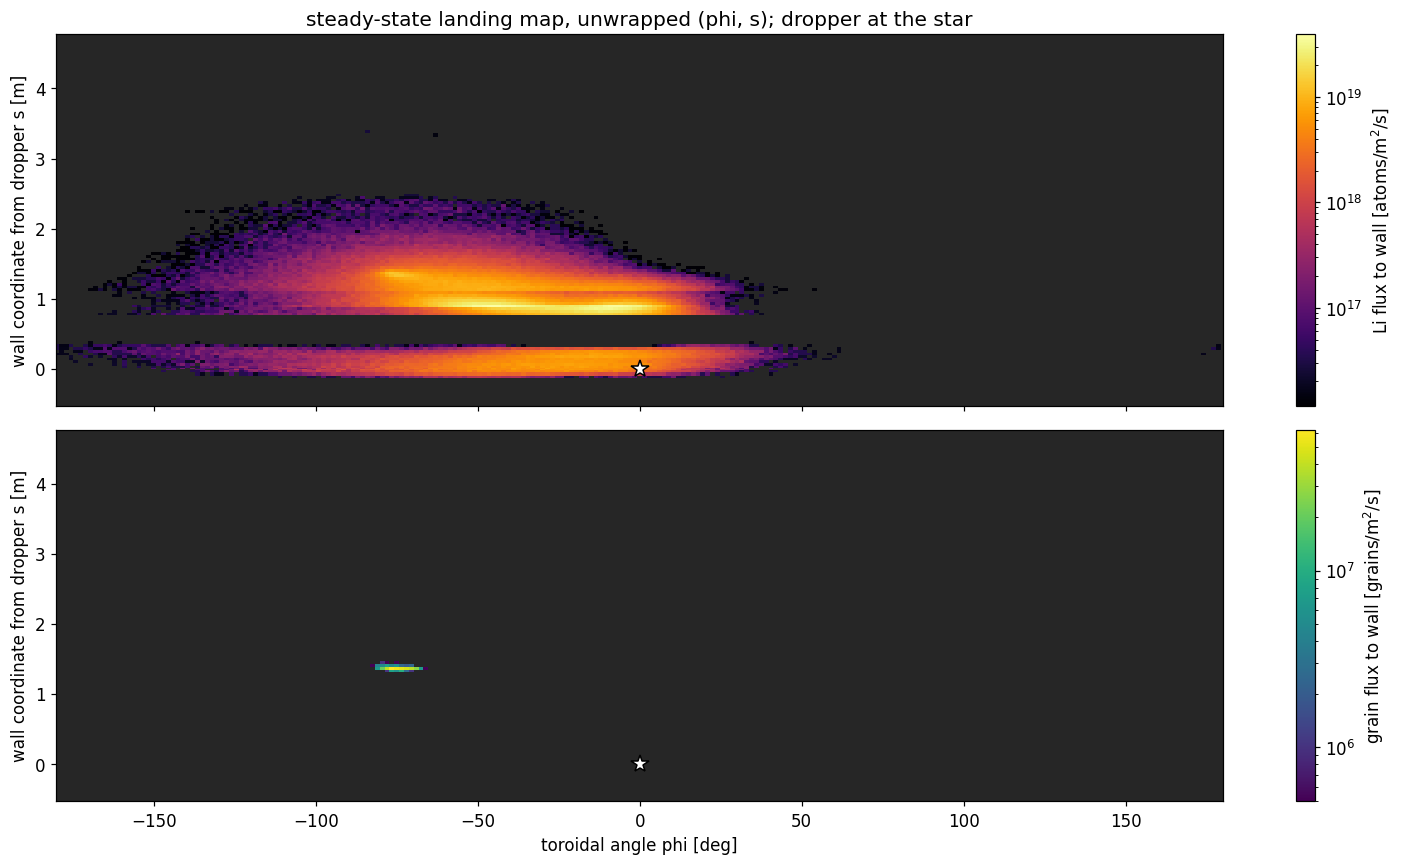

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ext = [phi_c[0] - DPHI/2, phi_c[-1] + DPHI/2, s_edge[0] - s0, s_edge[-1] - s0]
pos = LI_FLUX > 0
edges_phi = np.append(phi_c - DPHI/2, phi_c[-1] + DPHI/2)
if pos.any():
    im = ax[0].pcolormesh(edges_phi, s_edge - s0, np.where(pos, LI_FLUX, np.nan),
                          norm=LogNorm(vmin=max(LI_FLUX[pos].min(), LI_FLUX[pos].max() * 1e-4), vmax=LI_FLUX[pos].max()), cmap="inferno")
    fig.colorbar(im, ax=ax[0], label="Li flux to wall [atoms/m$^2$/s]")
else:
    ax[0].text(0, 0.5, "no Li reached the wall in the window", color="w", ha="center")
gpos = GR > 0
if gpos.any():
    im2 = ax[1].pcolormesh(edges_phi, s_edge - s0, np.where(gpos, GR / AREA, np.nan), norm=LogNorm(), cmap="viridis")
    fig.colorbar(im2, ax=ax[1], label="grain flux to wall [grains/m$^2$/s]")
else:
    ax[1].text(0, 0.5, "no grain reached the wall in the window", color="w", ha="center")
for a in ax:
    a.plot(0, 0, "w*", ms=12, mec="k"); a.set_ylabel("wall coordinate from dropper s [m]"); a.set_facecolor("0.15")
    a.set_xlim(-180, 180)
ax[0].set_title("steady-state landing map, unwrapped (phi, s); dropper at the star")
ax[1].set_xlabel("toroidal angle phi [deg]")
plt.tight_layout(); plt.show()

## Poloidal and toroidal deposition profiles

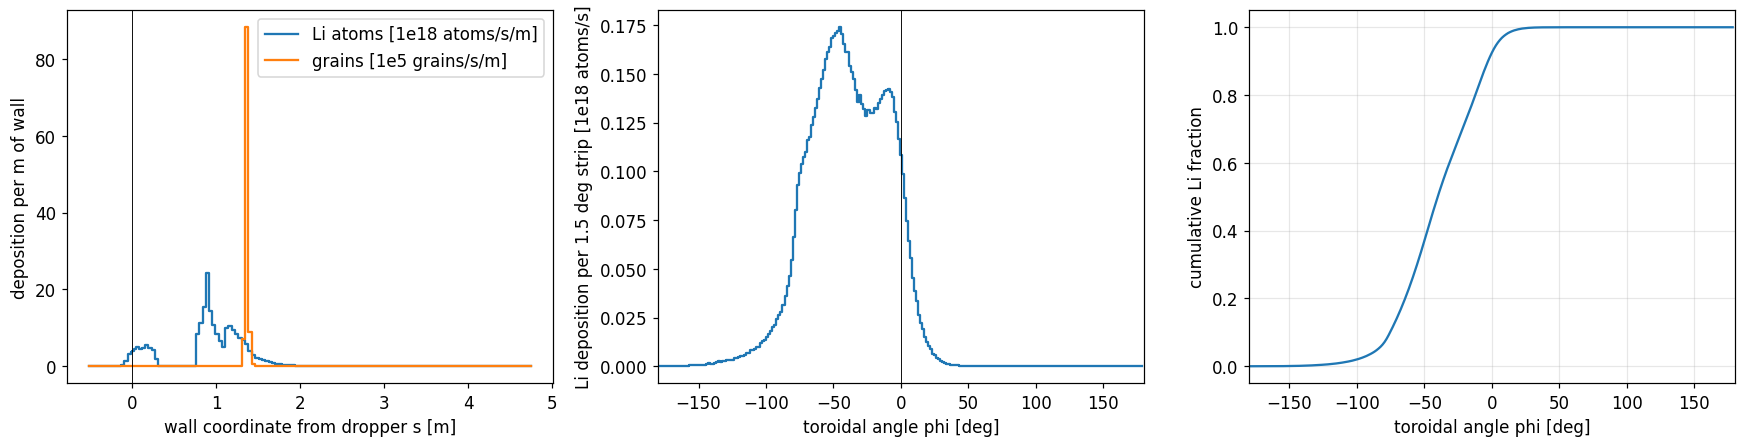

Li lands at phi = -38.9 deg (mean), spatial spread sd 28.6 deg, 90% between -85 and 4 deg
  s = +0.894 m  (R=0.643, Z=+0.556)  8.3% of the Li
  s = +0.860 m  (R=0.630, Z=+0.583)  7.2% of the Li
  s = +0.929 m  (R=0.676, Z=+0.548)  6.7% of the Li
  s = +0.820 m  (R=0.630, Z=+0.623)  5.3% of the Li
  s = +0.969 m  (R=0.716, Z=+0.548)  5.1% of the Li


In [5]:
pol = LI.sum(axis=1) / seg_len                 # atoms/s per m of poloidal wall (all phi)
tor = LI.sum(axis=0)                           # atoms/s per strip
gpol = GR.sum(axis=1) / seg_len
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].step(s_mid_d, pol / 1e18, where="mid", label="Li atoms [1e18 atoms/s/m]"); ax[0].step(s_mid_d, gpol / 1e5, where="mid", label="grains [1e5 grains/s/m]")
ax[0].set(xlabel="wall coordinate from dropper s [m]", ylabel="deposition per m of wall"); ax[0].legend(); ax[0].axvline(0, c="k", lw=0.6)
ax[1].step(phi_c, tor / 1e18, where="mid"); ax[1].set(xlabel="toroidal angle phi [deg]", ylabel="Li deposition per 1.5 deg strip [1e18 atoms/s]", xlim=(-180, 180)); ax[1].axvline(0, c="k", lw=0.6)
cum = np.cumsum(tor[::-1])[::-1] / tor.sum()   # fraction landing at angles >= phi
ax[2].plot(phi_c, np.cumsum(tor) / tor.sum()); ax[2].set(xlabel="toroidal angle phi [deg]", ylabel="cumulative Li fraction", xlim=(-180, 180)); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()
w = tor / tor.sum() if tor.sum() > 0 else np.full_like(tor, np.nan)
phi_mean = (w * phi_c).sum(); phi_sd = np.sqrt((w * (phi_c - phi_mean) ** 2).sum())
p5, p95 = np.interp([0.05, 0.95], np.cumsum(w), phi_c) if tor.sum() > 0 else (np.nan, np.nan)
print(f"Li lands at phi = {phi_mean:.1f} deg (mean), spatial spread sd {phi_sd:.1f} deg, 90% between {p5:.0f} and {p95:.0f} deg")
top = np.argsort(pol)[::-1][:5]
for k in top:
    print(f"  s = {s_mid_d[k]:+.3f} m  (R={seg_mid[k,0]:.3f}, Z={seg_mid[k,1]:+.3f})  {100*LI[k].sum()/li_wall:.1f}% of the Li")

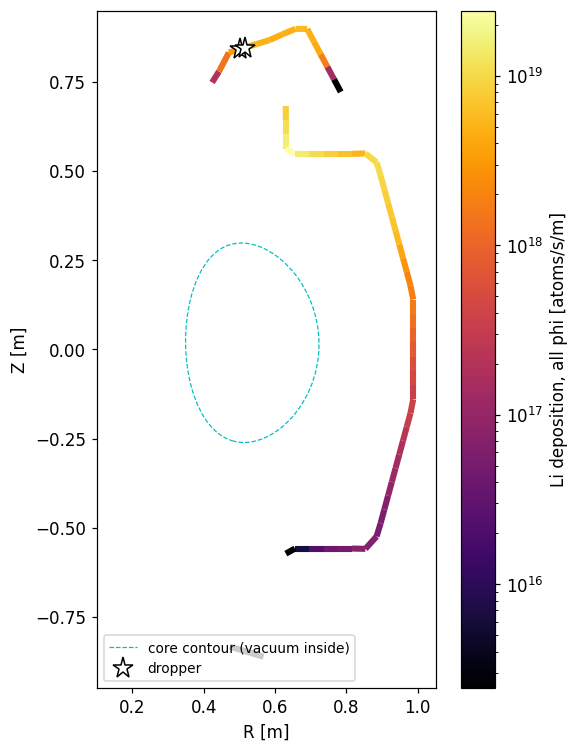

In [6]:
# poloidal view: the 2-D wall coloured by its toroidally integrated Li deposition
from matplotlib.collections import LineCollection
segs = np.stack([WALL, np.roll(WALL, -1, axis=0)], axis=1)
fig, ax = plt.subplots(figsize=(6, 8))
lc = LineCollection(segs, cmap="inferno", norm=LogNorm(vmin=max(pol[pol > 0].min(), pol.max() * 1e-4), vmax=pol.max()) if (pol > 0).any() else None, linewidths=4)
lc.set_array(np.where(pol > 0, pol, np.nan)); ax.add_collection(lc)
ax.plot(*np.vstack([CORE, CORE[:1]]).T, "c--", lw=0.8, label="core contour (vacuum inside)")
ax.plot(seg_mid[drop_k, 0], seg_mid[drop_k, 1], "w*", ms=14, mec="k", label="dropper")
fig.colorbar(lc, ax=ax, label="Li deposition, all phi [atoms/s/m]")
ax.set(xlabel="R [m]", ylabel="Z [m]", aspect="equal", xlim=(0.1, 1.05), ylim=(-0.95, 0.95)); ax.legend(loc="lower left", fontsize=9)
plt.show()

## The plume: toroidal sweep and the core-hole check

The core contour (psi_N 0.615) is vacuum in `plasma.h5` and there is no surface
there in this deck, so a grain that crossed it would keep falling unheated. Check
every particle state for grains inside it.

In [7]:
core_path = MplPath(CORE)
sfiles = sorted(glob.glob(str(OUT / "state.*.vtu")), key=lambda p: int(re.findall(r"\d+", p)[-1]))
rows = []
for f in sfiles:
    m = pv.read(f); P = np.asarray(m.points); typ = np.asarray(m["type"])
    g = P[typ == 1]
    if len(g) == 0: rows.append((int(re.findall(r"\d+", f)[-1]), 0, 0, np.nan, np.nan, np.nan, np.nan, np.nan)); continue
    R = np.hypot(g[:, 0], g[:, 1]); phi = np.degrees(np.arctan2(g[:, 1], g[:, 0]))
    inside = core_path.contains_points(np.column_stack([R, g[:, 2]]))
    d = np.min(np.hypot(R[:, None] - CORE[None, :, 0], g[:, 2][:, None] - CORE[None, :, 1]), axis=1)
    rows.append((int(re.findall(r"\d+", f)[-1]), len(g), inside.sum(), d.min(), np.percentile(phi, 1), np.median(phi), np.percentile(phi, 99), g[:, 2].min()))
print(" step   grains  in_core  min_dist_to_core[m]  phi 1% / median / 99% [deg]  Zmin[m]")
for r in rows:
    print(f"{r[0]:>6d} {r[1]:>8d} {r[2]:>8d} {r[3]:>14.3f}        {r[4]:>6.1f} / {r[5]:>6.1f} / {r[6]:>6.1f}      {r[7]:+.3f}")
total_in = sum(r[2] for r in rows)
print("RESULT: no grain observed inside the core contour at any saved snapshot (every ndump steps)" if total_in == 0 else f"RESULT: {total_in} grain samples inside the core contour: extrapolate the background into the core or restore the core torus")

 step   grains  in_core  min_dist_to_core[m]  phi 1% / median / 99% [deg]  Zmin[m]
     0        0        0            nan           nan /    nan /    nan      +nan
  2500      605        0          0.537          -0.7 /   -0.0 /    0.8      +0.835
  5000     1249        0          0.529          -0.8 /   -0.0 /    0.8      +0.827
  7500     1844        0          0.521          -0.9 /   -0.0 /    0.9      +0.819
 10000     2494        0          0.513          -1.0 /   -0.0 /    1.0      +0.811
 12500     3093        0          0.504          -1.1 /   -0.0 /    1.1      +0.803
 15000     3743        0          0.496          -1.2 /   -0.0 /    1.2      +0.794
 17500     4334        0          0.487          -1.3 /   -0.0 /    1.3      +0.785
 20000     4981        0          0.477          -1.4 /   -0.0 /    1.4      +0.776
 22500     5591        0          0.468          -1.5 /   -0.0 /    1.5      +0.766
 25000     6239        0          0.458          -1.6 /   -0.0 /    1.6      +0

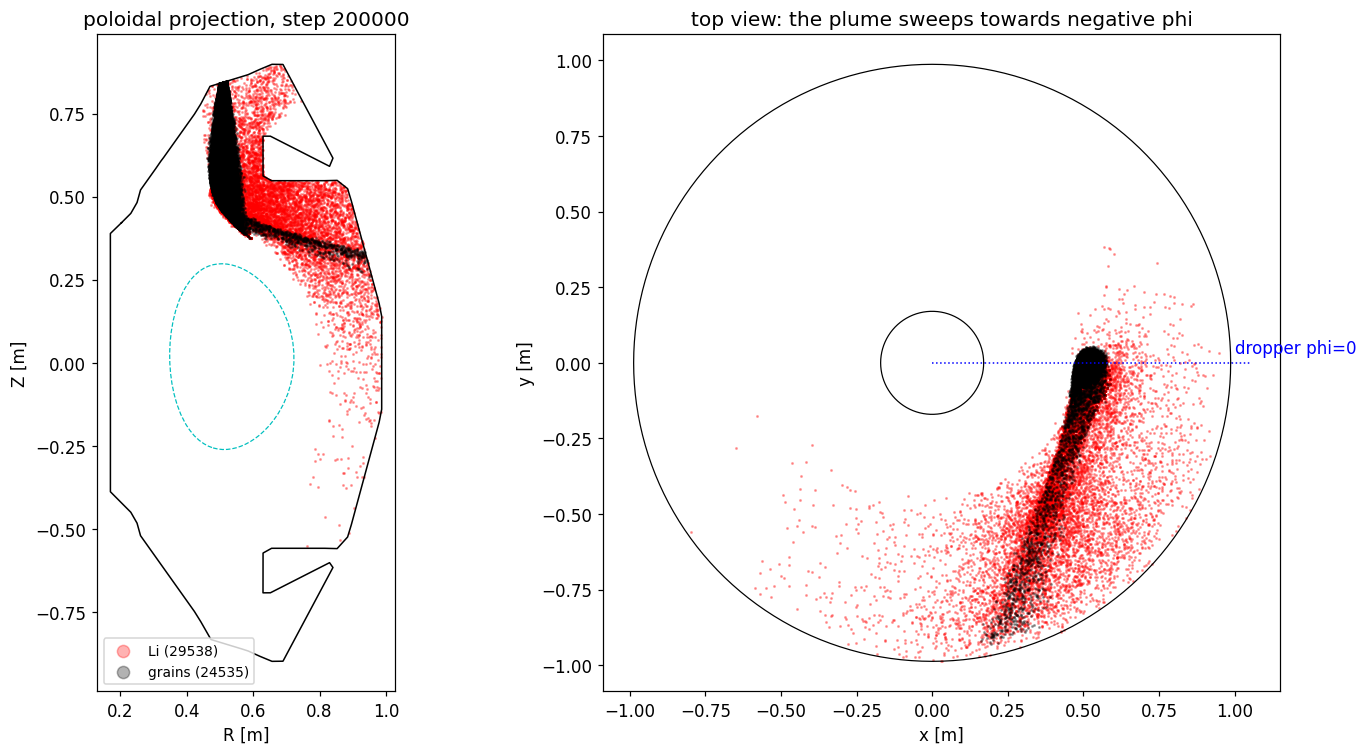

In [8]:
m = pv.read(sfiles[-1]); P = np.asarray(m.points); typ = np.asarray(m["type"])
g, li = P[typ == 1], P[typ == 2]
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].plot(*np.vstack([WALL, WALL[:1]]).T, "k-", lw=1); ax[0].plot(*np.vstack([CORE, CORE[:1]]).T, "c--", lw=0.8)
ax[0].scatter(np.hypot(li[:, 0], li[:, 1]), li[:, 2], s=1, c="r", alpha=0.3, label=f"Li ({len(li)})")
ax[0].scatter(np.hypot(g[:, 0], g[:, 1]), g[:, 2], s=1, c="k", alpha=0.3, label=f"grains ({len(g)})")
ax[0].set(xlabel="R [m]", ylabel="Z [m]", aspect="equal", title=f"poloidal projection, step {steps[-1]}"); ax[0].legend(markerscale=8, fontsize=9)
th = np.linspace(0, 2 * np.pi, 361)
for r in (WALL[:, 0].min(), WALL[:, 0].max()): ax[1].plot(r * np.cos(th), r * np.sin(th), "k-", lw=0.8)
ax[1].scatter(li[:, 0], li[:, 1], s=1, c="r", alpha=0.3); ax[1].scatter(g[:, 0], g[:, 1], s=1, c="k", alpha=0.3)
ax[1].plot([0, 1.05], [0, 0], "b:", lw=1); ax[1].text(1.0, 0.03, "dropper phi=0", color="b")
ax[1].set(xlabel="x [m]", ylabel="y [m]", aspect="equal", title="top view: the plume sweeps towards negative phi")
plt.tight_layout(); plt.show()

## Lithium cloud: toroidal distribution of the Li atoms (last density window)

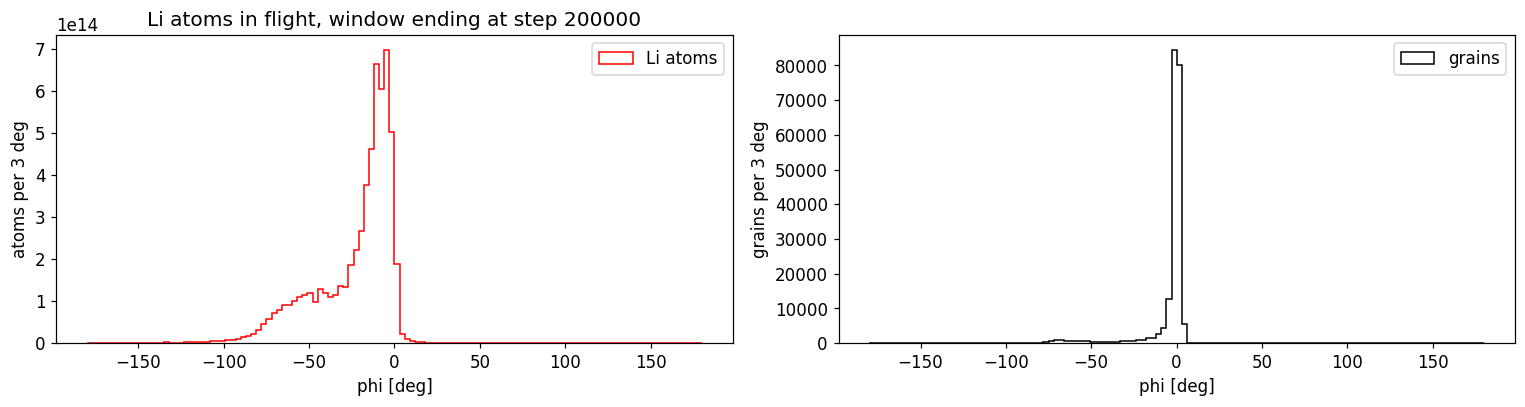

Li atoms in flight 6.100e+15 (= 30501 macroparticles), grains 204996


In [9]:
dfiles = sorted(glob.glob(str(OUT / "li_dens.*.vtu")), key=lambda p: int(re.findall(r"\d+", p)[-1]))
dstep = int(re.findall(r"\d+", dfiles[-1])[-1])
d = pv.read(dfiles[-1]); cc = d.cell_centers().points
vol = np.asarray(d.compute_cell_sizes(length=False, area=False, volume=True)["Volume"])
n_li = np.asarray(d["f_fli[2]"]) * vol                      # Li atoms per cell (pweight-weighted density)
n_gr = np.asarray(d["f_fli[1]"]) * vol / FNUM * NWEIGHT       # grains per cell (grain pweight = fnum per macro-grain)
phi_cell = np.degrees(np.arctan2(cc[:, 1], cc[:, 0])); R_cell = np.hypot(cc[:, 0], cc[:, 1])
bins = np.arange(-180, 181, 3)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(phi_cell, bins=bins, weights=n_li, histtype="step", color="r", label="Li atoms"); ax[0].set(xlabel="phi [deg]", ylabel="atoms per 3 deg", title=f"Li atoms in flight, window ending at step {dstep}")
ax[0].legend()
ax[1].hist(phi_cell, bins=bins, weights=n_gr, histtype="step", color="k", label="grains"); ax[1].set(xlabel="phi [deg]", ylabel="grains per 3 deg"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Li atoms in flight {n_li.sum():.3e} (= {n_li.sum()/FNUM:.0f} macroparticles), grains {n_gr.sum():.0f}")

## Summary

- Steady ionization fraction and the Li wall deposition rate are printed above with the atom balance.
- The landing map is an arc towards negative phi: the grains pick up toroidal velocity from ion drag while
  falling, and the Li they emit ionizes within millimetres of the grain, so the deposition follows the grain
  trajectories rather than the Li atoms' own motion.
- The core-hole check table says whether a grain was ever seen inside the vacuum core at a saved snapshot.